In [1]:
%pip install pandas openpyxl matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

In [4]:
file_path = "C:/Users/shubh/OneDrive/Documents/Data Analysis/retail-sales-analysis/data/raw/sample_-_superstore.xls"

df = pd.read_excel(file_path, 
sheet_name="Orders", 
engine="xlrd")

df.head()

C:\Users\shubh\AppData\Local\Temp\ipykernel_23412\2706279672.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file_path,


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [5]:
df.shape

(10194, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [7]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [8]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country/Region',
 'City',
 'State/Province',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print("Unique Row IDs:", df["Row ID"].nunique())
print("Unique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())

print(
    "Order Date Range:",
    df["Order Date"].min(),
    "to",
    df["Order Date"].max()
)



Unique Row IDs: 10194
Unique Orders: 5111
Unique Customers: 804
Order Date Range: 2023-01-03 00:00:00 to 2026-12-30 00:00:00


In [11]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,228.225854,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,10194.0,3.791838,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,10194.0,0.155385,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,10194.0,28.673417,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


In [12]:
cutoff_date = pd.Timestamp("2026-10-24")

future_orders = df[df["Order Date"] > cutoff_date]

print("Rows with future order dates:", len(future_orders))
print(
    "Distinct orders with future dates:",
    future_orders["Order ID"].nunique()
)

future_orders[
    ["Order ID", "Order Date", "Ship Date", "Customer Name", "Product Name"]
].head(10)

Rows with future order dates: 999
Distinct orders with future dates: 523


,Order ID,Order Date,Ship Date,Customer Name,Product Name
9195,US-2026-162173,2026-10-26,2026-11-01,Olvera Toch,"Lesro Sheffield Collection Coffee Table, End T..."
9196,US-2026-115119,2026-10-26,2026-10-30,Shaun Chance,"Premium Transparent Presentation Covers, No Pa..."
9197,US-2026-110646,2026-10-26,2026-10-31,Jamie Frazer,"GBC Velobind Prepunched Cover Sets, Regency Se..."
9198,US-2026-162173,2026-10-26,2026-11-01,Olvera Toch,"Tyvek Top-Opening Peel & Seel Envelopes, Gray"
9199,US-2026-155558,2026-10-26,2026-11-02,Paul Gonzalez,Avery 511
9200,US-2026-110646,2026-10-26,2026-10-31,Jamie Frazer,Avery 517
9201,US-2026-102729,2026-10-26,2026-10-31,Benjamin Farhat,"Multi-Use Personal File Cart and Caster Set, T..."
9202,US-2026-155558,2026-10-26,2026-11-02,Paul Gonzalez,Logitech LS21 Speaker System - PC Multimedia -...
9203,US-2026-115119,2026-10-26,2026-10-30,Shaun Chance,Cisco Small Business SPA 502G VoIP phone
9204,US-2026-110646,2026-10-26,2026-10-31,Jamie Frazer,Motorla HX550 Universal Bluetooth Headset


In [13]:
invalid_ship_dates = df[df["Ship Date"] < df["Order Date"]]

print("Records shipped before ordering:", len(invalid_ship_dates))

invalid_ship_dates[["Order ID", "Order Date", "Ship Date", "Ship Mode"]].head(10)

Records shipped before ordering: 0


,Order ID,Order Date,Ship Date,Ship Mode


In [14]:
future_orders = df[df["Order Date"] > cutoff_date].copy()

future_orders["Order Year"] = future_orders["Order Date"].dt.year
future_orders["Order Month"] = future_orders["Order Date"].dt.to_period("M")

print("Future-dated records by year:")
display(future_orders["Order Year"].value_counts().sort_index())

print("\nFuture-dated records by month:")
display(future_orders["Order Month"].value_counts().sort_index())

Future-dated records by year:


Order Year
2026    999
Name: count, dtype: int64


Future-dated records by month:


Order Month
2026-10     57
2026-11    460
2026-12    482
Freq: M, Name: count, dtype: int64

In [15]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Total Quantity Sold:", df["Quantity"].sum())

profit_margin = df["Profit"].sum() / df["Sales"].sum() * 100
print("Overall Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2326534.35
Total Profit: 292296.81
Total Quantity Sold: 38654
Overall Profit Margin: 12.56 %


In [16]:
category_performance = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Order_Count=("Order ID", "nunique")
    )
    .sort_values("Total_Profit", ascending=False)
)

category_performance["Profit_Margin_%"] = (
    category_performance["Total_Profit"]
    / category_performance["Total_Sales"]
    * 100
)

category_performance.round(2)

,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
Category,,,,,
Technology,839893.28,146543.38,7017,1560,17.45
Office Supplies,731893.31,126023.44,23268,3812,17.22
Furniture,754747.76,19730.00,8369,1819,2.61


Furniture needs inspection

In [17]:
subcategory_performance = (
    df.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Order_Count=("Order ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
)

subcategory_performance["Profit_Margin_%"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Sales"]
    * 100
)

subcategory_performance = (
    subcategory_performance
    .sort_values("Profit_Margin_%")
)

subcategory_performance.round(2)


Total_Sales  Total_Profit  Units_Sold  \
Category        Sub-Category                                          
Furniture       Tables          208020.18     -17753.21        1261   
                Bookcases       115361.20      -3632.07         878   
Office Supplies Supplies         46725.50      -1171.39         653   
Technology      Machines        189925.03       3461.98         442   
Furniture       Chairs          335768.25      27223.53        2431   
Office Supplies Storage         224644.55      21285.11        3191   
Technology      Phones          331842.64      45050.83        3357   
Furniture       Furnishings      95598.13      13891.74        3799   
Office Supplies Binders         207354.88      31426.10        6071   
                Appliances      108213.18      18329.48        1750   
                Art              27659.01       6653.20        3092   
Technology      Accessories     167380.32      41936.64        2976   
Office Supplies Fasteners         8532.24       2428.64         980   
Technology      Copiers         150745.29      56093.94         242   
Office Supplies Envelopes        16528.36       6988.02         914   
                Paper            79540.54      34511.51        5207   
                Labels           12695.04       5572.78        1410   

                              Order_Count  Average_Discount  Profit_Margin_%  
Category        Sub-Category                                                  
Furniture       Tables                314              0.26            -8.53  
                Bookcases             228              0.22            -3.15  
Office Supplies Supplies              189              0.08            -2.51  
Technology      Machines              114              0.30             1.82  
Furniture       Chairs                591              0.17             8.11  
Office Supplies Storage               787              0.08             9.48  
Technology      Phones                826              0.15            13.58  
Furniture       Furnishings           919              0.14            14.53  
Office Supplies Binders              1339              0.37            15.16  
                Appliances            459              0.16            16.94  
                Art                   756              0.08            24.05  
Technology      Accessories           718              0.08            25.05  
Office Supplies Fasteners             226              0.08            28.46  
Technology      Copiers                70              0.16            37.21  
Office Supplies Envelopes             251              0.08            42.28  
                Paper                1205              0.08            43.39  
                Labels                348              0.07            43.90

In [18]:
discount_analysis = (
    df.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Order_Count=("Order ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_index()
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"]
    * 100
)

discount_analysis.round(2)


,Total_Sales,Total_Profit,Average_Profit,Order_Count,Units_Sold,Profit_Margin_%
Discount,,,,,,
0.00,1105323.79,326718.59,66.34,2714,18770,29.56
0.10,54952.50,9099.97,94.79,91,377,16.56
0.15,27558.52,1418.99,27.29,51,198,5.15
0.20,773939.40,91079.95,24.58,2440,13856,11.77
0.30,104474.07,-10513.45,-45.71,214,855,-10.06
0.32,14493.46,-2391.14,-88.56,27,105,-16.50
0.40,116497.76,-23086.37,-111.53,186,789,-19.82
0.45,5484.97,-2493.11,-226.65,10,45,-45.45
0.50,58918.54,-20506.43,-310.70,64,241,-34.80


In [19]:
category_discount = (
    df.groupby(["Category", "Discount"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Row_Count=("Row ID", "count"),
        Average_Profit=("Profit", "mean")
    )
    .reset_index()
)

category_discount["Profit_Margin_%"] = (
    category_discount["Total_Profit"]
    / category_discount["Total_Sales"]
    * 100
)

category_discount = category_discount.sort_values(
    ["Category", "Discount"]
)

category_discount.round(2)


,Category,Discount,Total_Sales,Total_Profit,Row_Count,Average_Profit,Profit_Margin_%
0,Furniture,0.00,260155.06,59476.99,880,67.59,22.86
1,Furniture,0.10,47217.39,7181.80,78,92.07,15.21
2,Furniture,0.15,27558.52,1418.99,52,27.29,5.15
3,Furniture,0.20,223393.35,6608.50,636,10.39,2.96
4,Furniture,0.30,100191.18,-10786.83,224,-48.16,-10.77
5,Furniture,0.32,14493.46,-2391.14,27,-88.56,-16.50
6,Furniture,0.40,45614.41,-16187.40,75,-215.83,-35.49
7,Furniture,0.45,5484.97,-2493.11,11,-226.65,-45.45
8,Furniture,0.50,20983.47,-12871.20,54,-238.36,-61.34
9,Furniture,0.60,7051.98,-6134.07,147,-41.73,-86.98


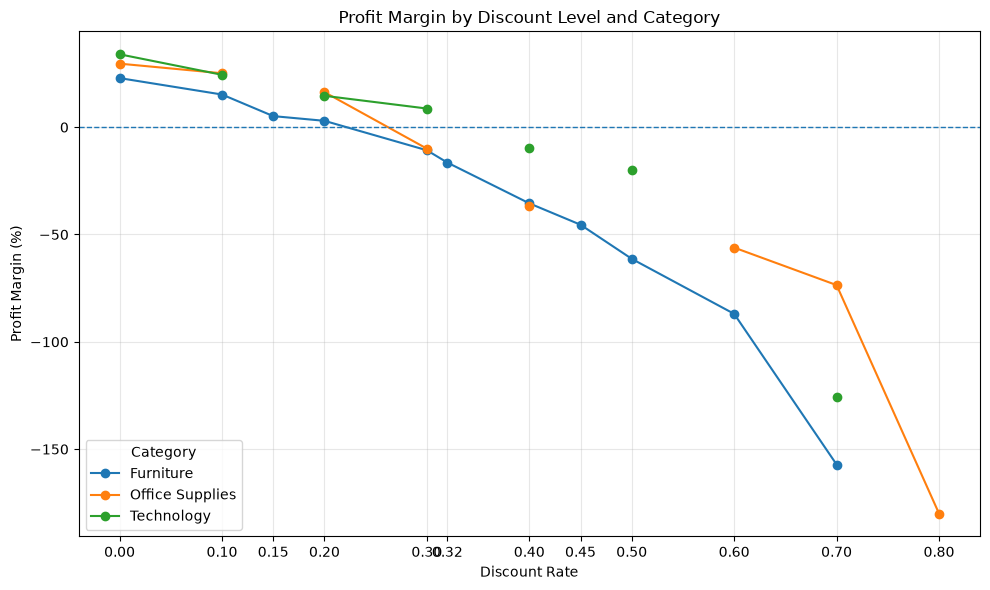

In [20]:
import matplotlib.pyplot as plt

margin_pivot = category_discount.pivot(
    index="Discount",
    columns="Category",
    values="Profit_Margin_%"
)

ax = margin_pivot.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.axhline(y=0, linestyle="--", linewidth=1)
ax.set_title("Profit Margin by Discount Level and Category")
ax.set_xlabel("Discount Rate")
ax.set_ylabel("Profit Margin (%)")
ax.set_xticks(margin_pivot.index)
ax.grid(True, alpha=0.3)
ax.legend(title="Category")
plt.tight_layout()
plt.show()


Discount and Profitability Analysis: Higher discount levels were generally associated with lower profit margins across the three product categories. Furniture showed negative profitability from the 30% discount level in the observed data, while Technology became unprofitable at 40%. Office Supplies experienced substantial losses at 70% and 80% discounts. These patterns suggest that discount policies should be reviewed by category, while accounting for product mix and sample size before setting discount limits.

In [21]:

# Check how many records and orders appear in each year
df["Order_Year"] = df["Order Date"].dt.year

yearly_summary = (
    df.groupby("Order_Year")
    .agg(
        Row_Count=("Row ID", "count"),
        Order_Count=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

yearly_summary.round(2)


,Row_Count,Order_Count,Total_Sales,Total_Profit
Order_Year,,,,
2023,2051,995,494040.21,51684.30
2024,2130,1053,472993.03,62020.97
2025,2634,1340,613933.58,82665.20
2026,3379,1723,745567.53,95926.35


In [22]:
# Examine the number of records in each month of 2026
orders_2026 = df[df["Order Date"].dt.year == 2026].copy()

monthly_2026 = (
    orders_2026
    .groupby(orders_2026["Order Date"].dt.month)
    .agg(
        Row_Count=("Row ID", "count"),
        Order_Count=("Order ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

monthly_2026.index.name = "Month"
monthly_2026.round(2)

,Row_Count,Order_Count,Total_Sales,Total_Profit
Month,,,,
1,161,71,44259.21,7231.64
2,107,53,20301.13,1613.87
3,245,121,60728.48,15013.09
4,204,117,36779.04,957.53
5,247,121,45155.48,6299.81
6,246,134,53056.08,8246.57
7,230,112,45989.50,7006.50
8,223,114,64129.76,9488.07
9,465,231,88064.53,11050.80


In [23]:

# Inspect the latest 10 order records
df.sort_values("Order Date", ascending=False)[
    ["Order ID", "Order Date", "Ship Date", "Category", "Sales", "Profit"]
].head(10)


,Order ID,Order Date,Ship Date,Category,Sales,Profit
10193,CA-2026-143500,2026-12-30,2027-01-03,Office Supplies,3.024,-0.6048
10192,US-2026-143259,2026-12-30,2027-01-03,Technology,90.930,2.7279
10191,US-2026-156720,2026-12-30,2027-01-03,Office Supplies,3.024,-0.6048
10190,US-2026-115427,2026-12-30,2027-01-03,Office Supplies,20.720,6.4750
10189,US-2026-143259,2026-12-30,2027-01-03,Office Supplies,52.776,19.7910
10188,US-2026-115427,2026-12-30,2027-01-03,Office Supplies,13.904,4.5188
10187,US-2026-126221,2026-12-30,2027-01-05,Office Supplies,209.300,56.5110
10186,US-2026-143259,2026-12-30,2027-01-03,Furniture,323.136,12.1176
10177,US-2026-158526,2026-12-29,2027-01-01,Office Supplies,34.580,10.0282
10171,US-2026-158526,2026-12-29,2027-01-01,Furniture,258.750,77.6250


In [24]:
# Create a monthly time period for each order
df["Order_Month"] = df["Order Date"].dt.to_period("M")

monthly_summary = (
    df.groupby("Order_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Order_Count=("Order ID", "nunique")
    )
)

monthly_summary.tail(12).round(2)

,Total_Sales,Total_Profit,Order_Count
Order_Month,,,
2026-01,44259.21,7231.64,71
2026-02,20301.13,1613.87,53
2026-03,60728.48,15013.09,121
2026-04,36779.04,957.53,117
2026-05,45155.48,6299.81,121
2026-06,53056.08,8246.57,134
2026-07,45989.50,7006.50,112
2026-08,64129.76,9488.07,114
2026-09,88064.53,11050.80,231


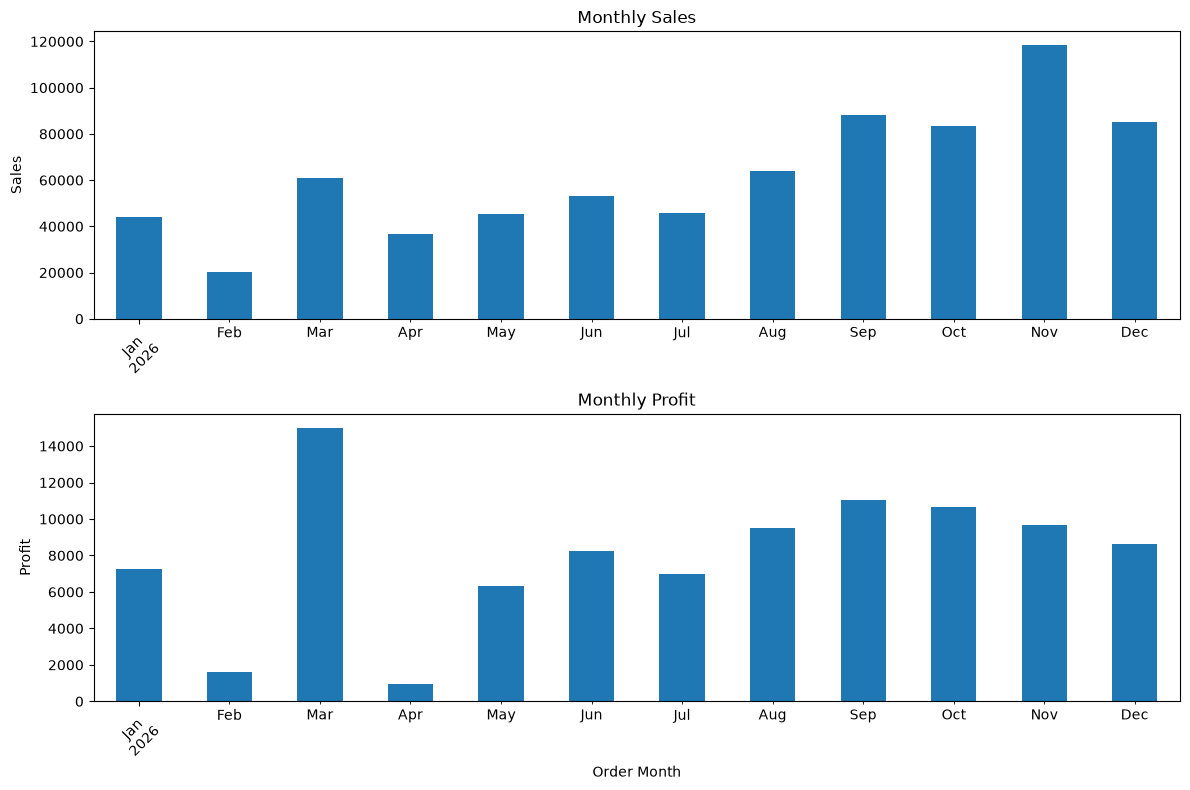

In [25]:
import matplotlib.pyplot as plt

recent_months = monthly_summary.tail(12)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

recent_months["Total_Sales"].plot(
    kind="bar", ax=axes[0], title="Monthly Sales"
)
axes[0].set_ylabel("Sales")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

recent_months["Total_Profit"].plot(
    kind="bar", ax=axes[1], title="Monthly Profit"
)
axes[1].set_ylabel("Profit")
axes[1].set_xlabel("Order Month")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [26]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_units = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100
average_order_value = total_sales / total_orders

kpi_summary = pd.Series({
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Orders": total_orders,
    "Unique Customers": total_customers,
    "Units Sold": total_units,
    "Profit Margin (%)": profit_margin,
    "Average Order Value": average_order_value
})

kpi_summary.round(2)

Total Sales            2326534.35
Total Profit            292296.81
Total Orders              5111.00
Unique Customers           804.00
Units Sold               38654.00
Profit Margin (%)           12.56
Average Order Value        455.20
dtype: float64

In [27]:
print("Earliest order:", df["Order Date"].min())
print("Latest order:", df["Order Date"].max())

print(
    "Rows after today:",
    (df["Order Date"] > pd.Timestamp("2026-10-24")).sum()
)

print("\nRecords per year:")
print(df.groupby(df["Order Date"].dt.year).size())

Earliest order: 2023-01-03 00:00:00
Latest order: 2026-12-30 00:00:00
Rows after today: 999

Records per year:
Order Date
2023    2051
2024    2130
2025    2634
2026    3379
dtype: int64


Recalculating 999 rows after cut_date. This doesn't mean those datas are invalid.

In [28]:

# Keep the original df unchanged
cutoff_date = pd.Timestamp("2026-10-24")

df_analysis = df.loc[
    df["Order Date"] <= cutoff_date
].copy()

print("Original rows:", len(df))
print("Analysis rows:", len(df_analysis))
print("Excluded future-dated rows:", len(df) - len(df_analysis))
print("Latest analysis date:", df_analysis["Order Date"].max())


Original rows: 10194
Analysis rows: 9195
Excluded future-dated rows: 999
Latest analysis date: 2026-10-24 00:00:00


In [29]:

total_sales = df_analysis["Sales"].sum()
total_profit = df_analysis["Profit"].sum()
total_orders = df_analysis["Order ID"].nunique()
total_customers = df_analysis["Customer ID"].nunique()
total_units = df_analysis["Quantity"].sum()

profit_margin = total_profit / total_sales * 100
average_order_value = total_sales / total_orders

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Units Sold: {total_units:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: {average_order_value:,.2f}")


Total Sales: 2,115,813.28
Total Profit: 273,117.69
Total Orders: 4,588
Unique Customers: 803
Units Sold: 34,787
Profit Margin: 12.91%
Average Order Value: 461.16


In [30]:

category_summary = (
    df_analysis.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Order_Count=("Order ID", "nunique")
    )
)

category_summary["Profit_Margin_%"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Sales"]
    * 100
)

category_summary = category_summary.sort_values(
    "Total_Profit", ascending=False
)

category_summary.round(2)


,Total_Sales,Total_Profit,Units_Sold,Order_Count,Profit_Margin_%
Category,,,,,
Technology,766427.33,135247.23,6325,1407,17.65
Office Supplies,666094.42,119828.75,20929,3432,17.99
Furniture,683291.53,18041.70,7533,1631,2.64


In [31]:

discount_summary = (
    df_analysis.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Row_Count=("Row ID", "count")
    )
)

discount_summary["Profit_Margin_%"] = (
    discount_summary["Total_Profit"]
    / discount_summary["Total_Sales"]
    * 100
)

discount_summary.round(2)


,Total_Sales,Total_Profit,Row_Count,Profit_Margin_%
Discount,,,,
0.00,999084.60,296383.55,4443,29.67
0.10,51190.48,8451.75,91,16.51
0.15,25037.44,1407.58,47,5.62
0.20,712341.21,84652.96,3336,11.88
0.30,96218.60,-9754.22,208,-10.14
0.32,13880.87,-2337.82,24,-16.84
0.40,106128.86,-20744.63,185,-19.55
0.45,4763.10,-2073.11,10,-43.52
0.50,49747.94,-16120.13,61,-32.40


In [32]:

subcategory_summary = (
    df_analysis.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
)

subcategory_summary["Profit_Margin_%"] = (
    subcategory_summary["Total_Profit"]
    / subcategory_summary["Total_Sales"]
    * 100
)

subcategory_summary = subcategory_summary.sort_values(
    "Total_Profit"
)

subcategory_summary.round(2)


Total_Sales  Total_Profit  Units_Sold  \
Category        Sub-Category                                          
Furniture       Tables          184795.12     -15822.42        1119   
                Bookcases       108827.77      -3115.69         804   
Office Supplies Supplies         43645.85      -1235.62         603   
                Fasteners         8119.84       2264.01         873   
                Labels           11965.88       5238.61        1303   
                Art              25330.87       6122.06        2749   
                Envelopes        15269.56       6435.45         841   
Technology      Machines        176914.68       7997.60         414   
Furniture       Furnishings      84245.84      12709.86        3403   
Office Supplies Appliances       93248.17      16107.50        1544   
                Storage         201631.48      18577.48        2865   
Furniture       Chairs          305422.80      24269.94        2207   
Office Supplies Paper            71780.58      31165.90        4700   
                Binders         195102.21      35153.37        5451   
Technology      Accessories     153488.44      38429.71        2649   
                Phones          304336.02      40702.04        3047   
                Copiers         131688.19      48117.88         215   

                              Average_Discount  Profit_Margin_%  
Category        Sub-Category                                     
Furniture       Tables                    0.26            -8.56  
                Bookcases                 0.22            -2.86  
Office Supplies Supplies                  0.08            -2.83  
                Fasteners                 0.08            27.88  
                Labels                    0.07            43.78  
                Art                       0.07            24.17  
                Envelopes                 0.08            42.15  
Technology      Machines                  0.30             4.52  
Furniture       Furnishings               0.14            15.09  
Office Supplies Appliances                0.16            17.27  
                Storage                   0.08             9.21  
Furniture       Chairs                    0.17             7.95  
Office Supplies Paper                     0.07            43.42  
                Binders                   0.37            18.02  
Technology      Accessories               0.08            25.04  
                Phones                    0.15            13.37  
                Copiers                   0.16            36.54

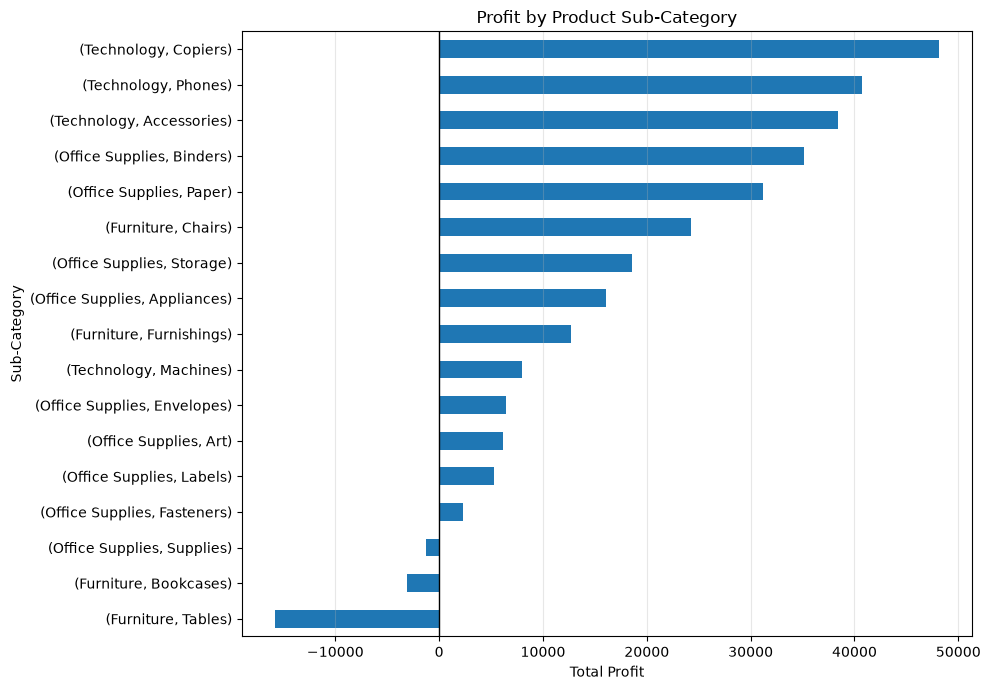

In [33]:

import matplotlib.pyplot as plt

profit_by_subcategory = (
    subcategory_summary["Total_Profit"]
    .sort_values()
)

ax = profit_by_subcategory.plot(
    kind="barh",
    figsize=(10, 7)
)

ax.axvline(x=0, color="black", linewidth=1)
ax.set_title("Profit by Product Sub-Category")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Sub-Category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


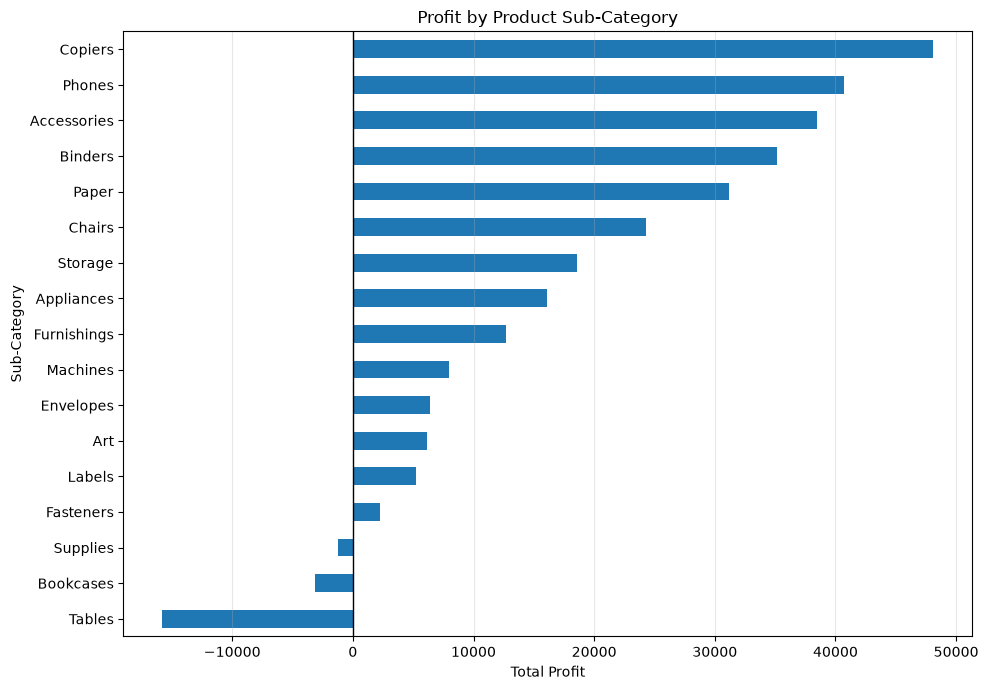

In [34]:
import matplotlib.pyplot as plt

profit_by_subcategory = (
    subcategory_summary["Total_Profit"]
    .sort_values()
)

# Display only the sub-category names
profit_by_subcategory.index = [
    subcategory[1]
    for subcategory in profit_by_subcategory.index
]

ax = profit_by_subcategory.plot(
    kind="barh",
    figsize=(10, 7)
)

ax.axvline(x=0, color="black", linewidth=1)
ax.set_title("Profit by Product Sub-Category")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Sub-Category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
# Create a copy so we don't modify our original dataset
df_trend = df_analysis.copy()

# Extract the month from each order date
df_trend["Order_Month"] = (
    df_trend["Order Date"].dt.to_period("M")
)

# Summarize sales, profit, and orders by month
monthly_summary = (
    df_trend.groupby("Order_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .sort_index()
)

monthly_summary.tail(12)

,Total_Sales,Total_Profit,Total_Orders
Order_Month,,,
2025-11,79411.9658,4011.4075,183
2025-12,97502.2770,17926.3013,185
2026-01,44259.2140,7231.6391,71
2026-02,20301.1334,1613.8720,53
2026-03,60728.4808,15013.0910,121
2026-04,36779.0361,957.5300,117
2026-05,45155.4822,6299.8072,121
2026-06,53056.0777,8246.5707,134
2026-07,45989.4960,7006.5012,112


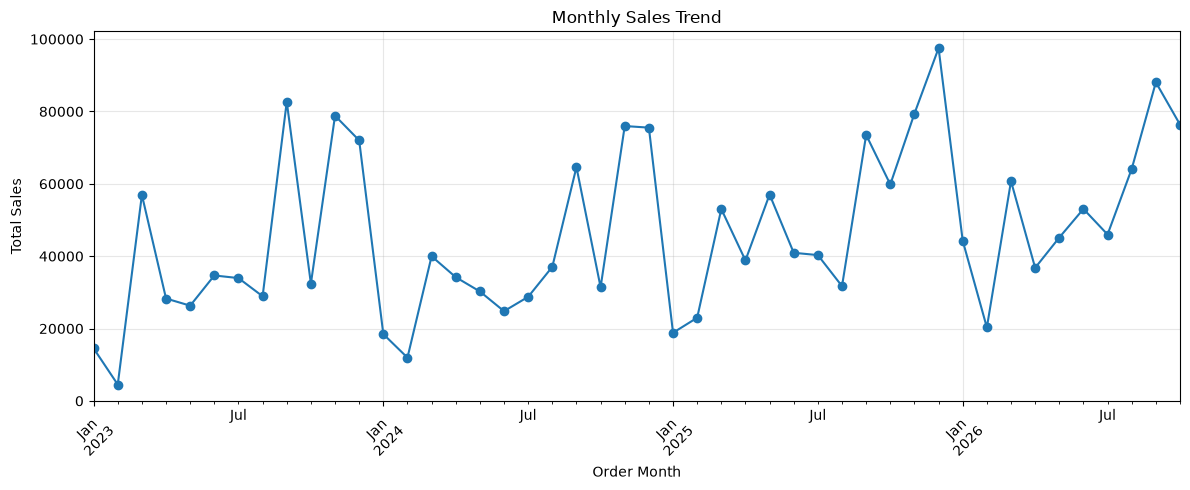

In [36]:
import matplotlib.pyplot as plt

monthly_sales = monthly_summary["Total_Sales"]

ax = monthly_sales.plot(
    figsize=(12, 5),
    marker="o"
)

ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Order Month")
ax.set_ylabel("Total Sales")
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

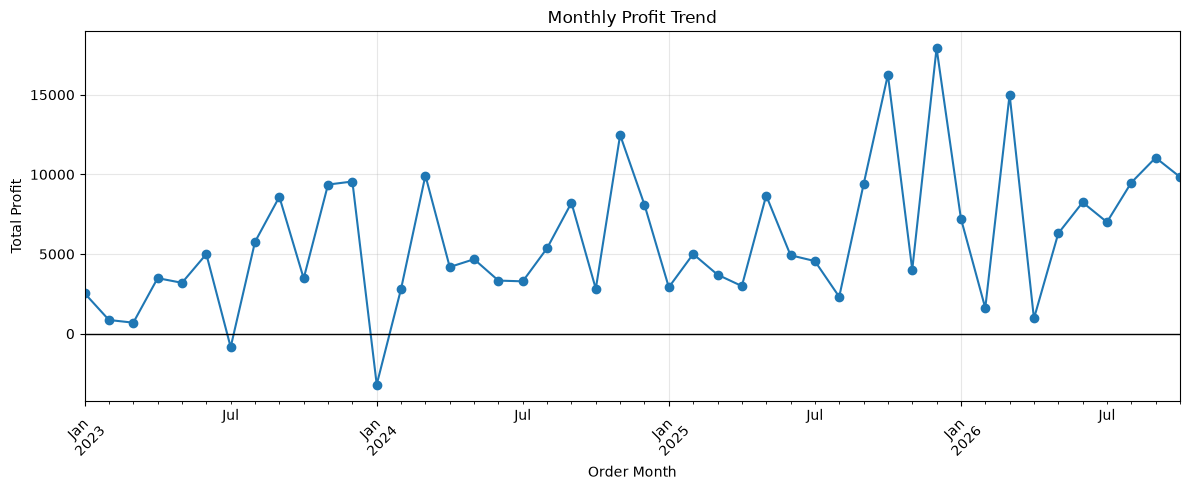

In [37]:
monthly_profit = monthly_summary["Total_Profit"]

ax = monthly_profit.plot(
    figsize=(12, 5),
    marker="o"
)

ax.axhline(y=0, color="black", linewidth=1)
ax.set_title("Monthly Profit Trend")
ax.set_xlabel("Order Month")
ax.set_ylabel("Total Profit")
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
monthly_summary["Profit_Margin_%"] = (
    monthly_summary["Total_Profit"]
    / monthly_summary["Total_Sales"]
    * 100
)

monthly_summary.tail(12).round(2)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%
Order_Month,,,,
2025-11,79411.97,4011.41,183,5.05
2025-12,97502.28,17926.30,185,18.39
2026-01,44259.21,7231.64,71,16.34
2026-02,20301.13,1613.87,53,7.95
2026-03,60728.48,15013.09,121,24.72
2026-04,36779.04,957.53,117,2.60
2026-05,45155.48,6299.81,121,13.95
2026-06,53056.08,8246.57,134,15.54
2026-07,45989.50,7006.50,112,15.24


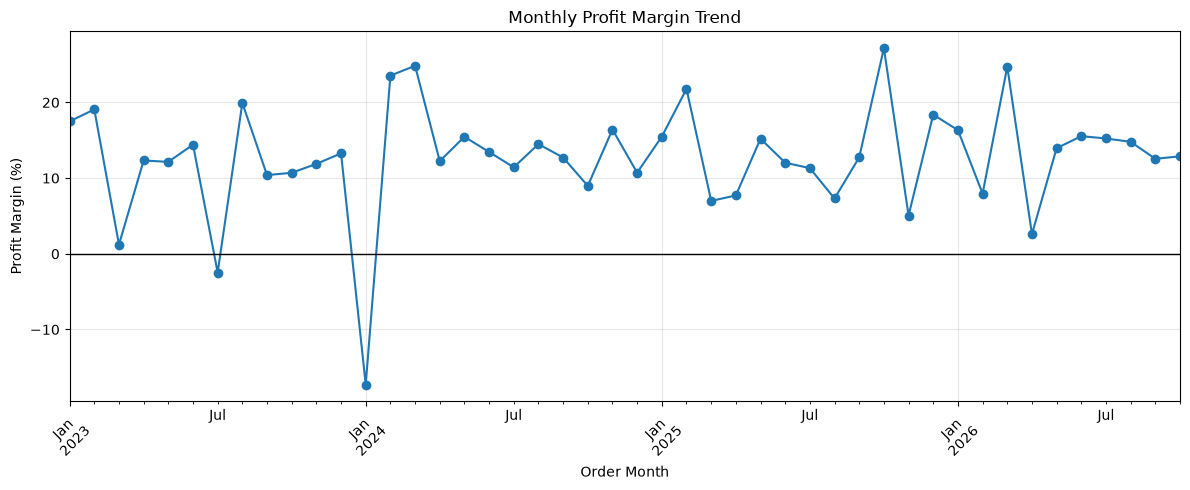

In [39]:
monthly_margin = monthly_summary["Profit_Margin_%"]

ax = monthly_margin.plot(
    figsize=(12, 5),
    marker="o"
)

ax.axhline(y=0, color="black", linewidth=1)
ax.set_title("Monthly Profit Margin Trend")
ax.set_xlabel("Order Month")
ax.set_ylabel("Profit Margin (%)")
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Monthly Sales and Profitability Insights

- Monthly sales and profit fluctuate considerably over the analyzed period.
- December 2025 recorded the highest monthly profit in the displayed data, at approximately 17,926.
- March 2026 achieved the highest monthly profit margin, at 24.72%.
- April 2026 had the lowest monthly margin among the displayed 2026 months, at 2.60%.
- November 2025 generated a 5.05% margin, while December 2025 achieved 18.39%, highlighting substantial variation in profitability.

**Business recommendation:** Investigate monthly changes in product mix, discount levels, and costs to understand why profitability varies. Evaluate performance using sales, total profit, and profit margin together rather than relying on sales alone.

*Note: These findings are descriptive, not proof of what caused the changes. Validate the dataset's reporting period and future-dated records before publishing the analysis.*

In [40]:
# Check the date range in the analysis dataset
print("First order:", df_analysis["Order Date"].min())
print("Last order:", df_analysis["Order Date"].max())

# Check how many rows and columns we have
print("Dataset shape:", df_analysis.shape)

# Preview the data
df_analysis.head()

First order: 2023-01-03 00:00:00
Last order: 2026-10-24 00:00:00
Dataset shape: (9195, 23)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order_Year,Order_Month
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023,2023-01
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023,2023-01
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2023,2023-01
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023,2023-01
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,2023,2023-01


In [41]:
from pathlib import Path

# Create the processed folder if it doesn't exist
output_dir = Path("C:/Users/shubh/OneDrive/Documents/Data Analysis/retail-sales-analysis/data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Remove the temporary monthly helper column if present
export_df = df_analysis.drop(
    columns=["Order_Month"],
    errors="ignore"
)

# Export the analysis dataset
output_path = output_dir / "superstore_analysis.csv"

export_df.to_csv(
    output_path,
    index=False
)

print("Export successful:", output_path.resolve())
print("Rows exported:", len(export_df))

Export successful: C:\Users\shubh\OneDrive\Documents\Data Analysis\retail-sales-analysis\data\processed\superstore_analysis.csv
Rows exported: 9195
